In [45]:
ozet3 = temiz.groupby("puan_grubu", observed=True)["beyaz_kazandi"].agg(["count", "mean"])
ozet3

,count,mean
puan_grubu,,
Siyah çok güçlü (200+),3052,0.209371
Siyah güçlü (50-200),4023,0.375590
Denk (±50),5432,0.487666
Beyaz güçlü (50-200),4264,0.613743
Beyaz çok güçlü (200+),3287,0.786431


In [46]:
sinirlar = [-np.inf, -200, -50, 50, 200, np.inf]
etiketler = [
    "Siyah çok güçlü (200+)",
    "Siyah güçlü (50-200)",
    "Denk (±50)",
    "Beyaz güçlü (50-200)",
    "Beyaz çok güçlü (200+)",
]

temiz["puan_grubu"] = pd.cut(temiz["puan_farki"], bins=sinirlar, labels=etiketler)
temiz[["puan_farki", "puan_grubu"]].head()

,puan_farki,puan_grubu
0,309,Beyaz çok güçlü (200+)
1,61,Beyaz güçlü (50-200)
2,-4,Denk (±50)
3,-15,Denk (±50)
4,54,Beyaz güçlü (50-200)


In [47]:
temiz["puan_farki"] = temiz["white_rating"] - temiz["black_rating"]
temiz["puan_farki"].describe()

count    20058.000000
mean         7.799880
std        249.036667
min      -1605.000000
25%       -108.000000
50%          3.000000
75%        122.000000
max       1499.000000
Name: puan_farki, dtype: float64

In [48]:
populer = populer.copy()
populer["beyaz_kazanma_%"] = (populer["mean"] * 100).round(1)
populer.sort_values("beyaz_kazanma_%", ascending=False).head(10)

,count,mean,beyaz_kazanma_%
opening_name,,,
Queen's Gambit Refused: Marshall Defense,127,0.661417,66.1
Queen's Pawn,129,0.658915,65.9
Philidor Defense #3,198,0.641414,64.1
Scandinavian Defense: Mieses-Kotroc Variation,259,0.633205,63.3
Philidor Defense,135,0.622222,62.2
Queen's Gambit Declined,116,0.594828,59.5
French Defense: Normal Variation,129,0.589147,58.9
Pirc Defense #4,107,0.588785,58.9
Italian Game,109,0.568807,56.9


In [49]:
populer = ozet2[ozet2["count"] >= 100]
populer.sort_values("mean", ascending=False).head(10)

,count,mean
opening_name,,
Queen's Gambit Refused: Marshall Defense,127,0.661417
Queen's Pawn,129,0.658915
Philidor Defense #3,198,0.641414
Scandinavian Defense: Mieses-Kotroc Variation,259,0.633205
Philidor Defense,135,0.622222
Queen's Gambit Declined,116,0.594828
French Defense: Normal Variation,129,0.589147
Pirc Defense #4,107,0.588785
Italian Game,109,0.568807


In [50]:
ozet2 = temiz.groupby("opening_name")["beyaz_kazandi"].agg(["count", "mean"])
ozet2.sort_values("mean", ascending=False).head(10)

,count,mean
opening_name,,
Alekhine Defense: Brooklyn Variation,2,1.0
Philidor Defense: Steinitz Variation,3,1.0
Pirc Defense: Austrian Attack | Unzicker Attack,3,1.0
Vienna Game: Omaha Gambit,1,1.0
Benko Gambit Accepted | Fianchetto Variation,2,1.0
Benko Gambit Accepted | Modern Variation,1,1.0
Benko Gambit Accepted | Pawn Return Variation,1,1.0
Benko Gambit Declined | Quiet Line,1,1.0
Alekhine Defense: Mokele Mbembe | Vavra Defense,4,1.0


In [51]:
temiz["beyaz_kazandi"] = temiz["winner"] == "white"
temiz[["winner", "beyaz_kazandi"]].head()

,winner,beyaz_kazandi
0,white,True
1,black,False
2,white,True
3,white,True
4,white,True


In [52]:
ozet1 = temiz.groupby("victory_status")["turns"].agg(["count", "mean", "median"])
ozet1

,count,mean,median
victory_status,,,
draw,906,83.781457,86.0
mate,6325,65.415020,59.0
outoftime,1680,72.742857,71.0
resign,11147,53.912533,50.0


In [53]:
mat_oyunlari = temiz[temiz["victory_status"] == "mate"]
print(mat_oyunlari["turns"].median())

59.0


In [54]:
temiz.groupby("victory_status")["turns"].median()

victory_status
draw         86.0
mate         59.0
outoftime    71.0
resign       50.0
Name: turns, dtype: float64

## Veri temizleme notları

- **Boş hücreler:** `isna().sum()` hiçbir sütunda boş hücre göstermedi.
- **Tekrar eden oyunlar:** 20058 oyun aynı `id` ile birden fazla kez geçiyordu. Aynı oyunun tekrarı istatistikleri çarpıtacağı için ilk kayıt tutulup tekrarlar silindi. Kalan oyun sayısı: 20058-945.
- **Gizli eksik değerler:** Z oyunda başlangıç ve bitiş zamanı aynıydı (süre = 0). Bu gerçek bir değer olamayacağı için kayıt hatası kabul edilip NaN yapıldı. Diğer sütunları geçerli olduğu için bu satırlar silinmedi, süre de uydurma bir değerle doldurulmadı.
- **Şüpheli ama gerçek değerler:** 194 oyun 3 hamleden kısa. Bunlar erken terk edilen oyunlar olabileceği için silinmedi, uzunluk analizlerinde dikkate alınacak.

In [55]:
print("En kısa oyun:", temiz["turns"].min(), "hamle")
print("3 hamleden kısa oyun sayısı:", (temiz["turns"] < 3).sum())
print("En düşük puan:", temiz[["white_rating", "black_rating"]].min().min())

En kısa oyun: 1 hamle
3 hamleden kısa oyun sayısı: 203
En düşük puan: 784


In [56]:
sureli = temiz.dropna(subset=["sure_dk"])

KeyError: ['sure_dk']

In [ ]:
print("Ortalama süre (NaN'lar hariç):", temiz["sure_dk"].mean())
print("Medyan süre:", temiz["sure_dk"].median())

Ortalama süre (NaN'lar hariç): 26.29856133427851
Medyan süre: 11.843091666666666


In [ ]:
ornek["kazanan"].fillna(ornek["kazanan"].mode()[0])

0    white
1    black
2    white
3    white
4    white
Name: kazanan, dtype: str

In [ ]:
ornek["puan"].fillna(ornek["puan"].median())

0    1500.0
1    1610.0
2    1720.0
3    1610.0
4    1610.0
Name: puan, dtype: float64

In [ ]:
ornek.dropna()

,puan,kazanan
0,1500.0,white
3,1610.0,white


In [ ]:
ornek = pd.DataFrame({
    "puan": [1500, np.nan, 1720, 1610, np.nan],
    "kazanan": ["white", "black", None, "white", "white"],
})
ornek

,puan,kazanan
0,1500.0,white
1,NaN,black
2,1720.0,NaN
3,1610.0,white
4,NaN,white


In [ ]:
temiz.loc[temiz["sure_dk"] == 0, "sure_dk"] = np.nan

temiz.isna().sum()

id                   0
rated                0
created_at           0
last_move_at         0
turns                0
victory_status       0
winner               0
increment_code       0
white_id             0
white_rating         0
black_id             0
black_rating         0
moves                0
opening_eco          0
opening_name         0
opening_ply          0
sure_dk           8533
dtype: int64

In [ ]:
sifir = (temiz["sure_dk"] == 0).sum()
print(f"Süresi 0 olan oyun: {sifir} ({sifir / len(temiz) * 100:.1f}%)")

Süresi 0 olan oyun: 8533 (44.6%)


In [ ]:
temiz["sure_dk"] = (temiz["last_move_at"] - temiz["created_at"]) / 1000 / 60
temiz["sure_dk"].describe()

count    19113.000000
mean        14.557567
std         82.122675
min          0.000000
25%          0.000000
50%          3.288133
75%         13.017533
max      10097.411683
Name: sure_dk, dtype: float64

In [ ]:
once = len(temiz)
temiz = temiz.drop_duplicates(subset="id", keep="first")
print(f"{once - len(temiz)} tekrar eden satır silindi. Yeni satır sayısı: {len(temiz)}")

945 tekrar eden satır silindi. Yeni satır sayısı: 19113


In [ ]:
print("Tamamen aynı satır sayısı:", temiz.duplicated().sum())
print("Tekrar eden id sayısı:", temiz["id"].duplicated().sum())

Tamamen aynı satır sayısı: 429
Tekrar eden id sayısı: 945


In [ ]:
temiz.isna().sum().sum()

np.int64(0)

In [ ]:
temiz.isna().sum()

id                0
rated             0
created_at        0
last_move_at      0
turns             0
victory_status    0
winner            0
increment_code    0
white_id          0
white_rating      0
black_id          0
black_rating      0
moves             0
opening_eco       0
opening_name      0
opening_ply       0
beyaz_kazandi     0
dtype: int64

In [ ]:
import numpy as np

temiz = df.copy()

-20058 kez oyun oynanmış
-Puan aralığı 700-2700 , 60 tur tipik oyun uzunluğu
-Victory status 4 

In [ ]:
df["victory_status"].value_counts()

victory_status
resign       11147
mate          6325
outoftime     1680
draw           906
Name: count, dtype: int64

In [ ]:
df["winner"].value_counts(normalize=True) * 100

winner
white    49.860405
black    45.403330
draw      4.736265
Name: proportion, dtype: float64

In [ ]:
df["winner"].value_counts()

winner
white    10001
black     9107
draw       950
Name: count, dtype: int64

In [ ]:
df.describe(include="object")

/tmp/ipykernel_6070/702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,id,victory_status,winner,increment_code,white_id,black_id,moves,opening_eco,opening_name
count,20058,20058,20058,20058,20058,20058,20058,20058,20058
unique,19113,4,3,400,9438,9331,18920,365,1477
top,XRuQPSzH,resign,white,10+0,taranga,taranga,e4 e5,A00,Van't Kruijs Opening
freq,5,11147,10001,7721,72,82,27,1007,368


In [ ]:
pd.to_datetime(df["created_at"], unit="ms").head()

0   2017-08-31 20:06:40
1   2017-08-30 21:53:20
2   2017-08-30 21:53:20
3   2017-08-30 16:20:00
4   2017-08-29 18:06:40
Name: created_at, dtype: datetime64[us]

In [ ]:
df.describe()

,created_at,last_move_at,turns,white_rating,black_rating,opening_ply
count,2.005800e+04,2.005800e+04,20058.000000,20058.000000,20058.000000,20058.000000
mean,1.483617e+12,1.483618e+12,60.465999,1596.631868,1588.831987,4.816981
std,2.850151e+10,2.850140e+10,33.570585,291.253376,291.036126,2.797152
min,1.376772e+12,1.376772e+12,1.000000,784.000000,789.000000,1.000000
25%,1.477548e+12,1.477548e+12,37.000000,1398.000000,1391.000000,3.000000
50%,1.496010e+12,1.496010e+12,55.000000,1567.000000,1562.000000,4.000000
75%,1.503170e+12,1.503170e+12,79.000000,1793.000000,1784.000000,6.000000
max,1.504493e+12,1.504494e+12,349.000000,2700.000000,2723.000000,28.000000


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20058 entries, 0 to 20057
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              20058 non-null  str    
 1   rated           20058 non-null  bool   
 2   created_at      20058 non-null  float64
 3   last_move_at    20058 non-null  float64
 4   turns           20058 non-null  int64  
 5   victory_status  20058 non-null  str    
 6   winner          20058 non-null  str    
 7   increment_code  20058 non-null  str    
 8   white_id        20058 non-null  str    
 9   white_rating    20058 non-null  int64  
 10  black_id        20058 non-null  str    
 11  black_rating    20058 non-null  int64  
 12  moves           20058 non-null  str    
 13  opening_eco     20058 non-null  str    
 14  opening_name    20058 non-null  str    
 15  opening_ply     20058 non-null  int64  
dtypes: bool(1), float64(2), int64(4), str(9)
memory usage: 2.3 MB


In [ ]:
df.columns

Index(['id', 'rated', 'created_at', 'last_move_at', 'turns', 'victory_status',
       'winner', 'increment_code', 'white_id', 'white_rating', 'black_id',
       'black_rating', 'moves', 'opening_eco', 'opening_name', 'opening_ply'],
      dtype='str')

In [ ]:
df.head()

,id,rated,created_at,last_move_at,turns,victory_status,winner,increment_code,white_id,white_rating,black_id,black_rating,moves,opening_eco,opening_name,opening_ply
0,TZJHLljE,False,1.504210e+12,1.504210e+12,13,outoftime,white,15+2,bourgris,1500,a-00,1191,d4 d5 c4 c6 cxd5 e6 dxe6 fxe6 Nf3 Bb4+ Nc3 Ba5...,D10,Slav Defense: Exchange Variation,5
1,l1NXvwaE,True,1.504130e+12,1.504130e+12,16,resign,black,5+10,a-00,1322,skinnerua,1261,d4 Nc6 e4 e5 f4 f6 dxe5 fxe5 fxe5 Nxe5 Qd4 Nc6...,B00,Nimzowitsch Defense: Kennedy Variation,4
2,mIICvQHh,True,1.504130e+12,1.504130e+12,61,mate,white,5+10,ischia,1496,a-00,1500,e4 e5 d3 d6 Be3 c6 Be2 b5 Nd2 a5 a4 c5 axb5 Nc...,C20,King's Pawn Game: Leonardis Variation,3
3,kWKvrqYL,True,1.504110e+12,1.504110e+12,61,mate,white,20+0,daniamurashov,1439,adivanov2009,1454,d4 d5 Nf3 Bf5 Nc3 Nf6 Bf4 Ng4 e3 Nc6 Be2 Qd7 O...,D02,Queen's Pawn Game: Zukertort Variation,3
4,9tXo1AUZ,True,1.504030e+12,1.504030e+12,95,mate,white,30+3,nik221107,1523,adivanov2009,1469,e4 e5 Nf3 d6 d4 Nc6 d5 Nb4 a3 Na6 Nc3 Be7 b4 N...,C41,Philidor Defense,5


In [ ]:
import pandas as pd

df = pd.read_csv("games.csv")
print(df.shape)

(20058, 16)


In [ ]:
ozet1 = temiz.groupby("victory_status")["turns"].agg(["count", "mean", "median"])
ozet1

,count,mean,median
victory_status,,,
draw,906,83.781457,86.0
mate,6325,65.415020,59.0
outoftime,1680,72.742857,71.0
resign,11147,53.912533,50.0


In [ ]:
temiz["beyaz_kazandi"] = temiz["winner"] == "white"

ozet2 = temiz.groupby("opening_name")["beyaz_kazandi"].agg(["count", "mean"])
populer = ozet2[ozet2["count"] >= 100]
populer.sort_values("mean", ascending=False).head(10)

,count,mean
opening_name,,
Queen's Gambit Refused: Marshall Defense,127,0.661417
Queen's Pawn,129,0.658915
Philidor Defense #3,198,0.641414
Scandinavian Defense: Mieses-Kotroc Variation,259,0.633205
Philidor Defense,135,0.622222
Queen's Gambit Declined,116,0.594828
French Defense: Normal Variation,129,0.589147
Pirc Defense #4,107,0.588785
Italian Game,109,0.568807


In [ ]:
import matplotlib.pyplot as plt

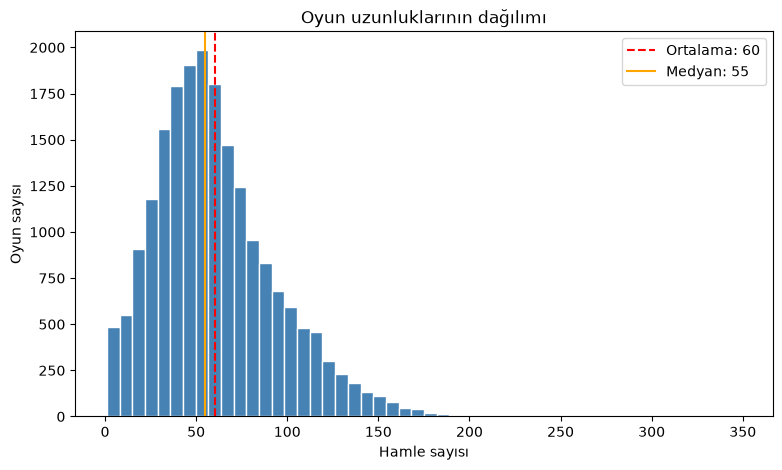

In [60]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(temiz["turns"], bins=50, color="steelblue", edgecolor="white")

ortalama = temiz["turns"].mean()
medyan = temiz["turns"].median()
ax.axvline(ortalama, color="red", linestyle="--", label=f"Ortalama: {ortalama:.0f}")
ax.axvline(medyan, color="orange", linestyle="-", label=f"Medyan: {medyan:.0f}")

ax.set_title("Oyun uzunluklarının dağılımı")
ax.set_xlabel("Hamle sayısı")
ax.set_ylabel("Oyun sayısı")
ax.legend()
plt.savefig("grafik_histogram.png", dpi=150, bbox_inches="tight")
plt.show()

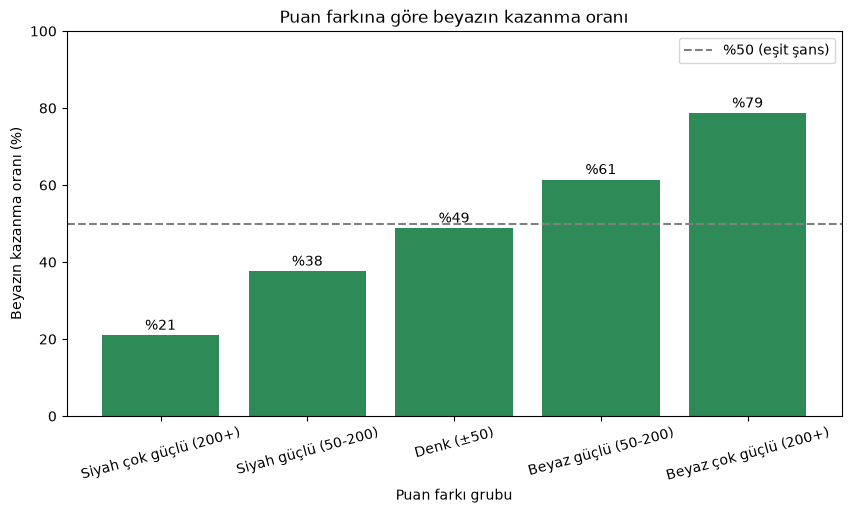

In [59]:
oranlar = ozet3["mean"] * 100

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(oranlar.index.astype(str), oranlar.values, color="seagreen")

ax.axhline(50, color="gray", linestyle="--", label="%50 (eşit şans)")

for i, deger in enumerate(oranlar.values):
    ax.text(i, deger + 1.5, f"%{deger:.0f}", ha="center")

ax.set_ylim(0, 100)
ax.set_title("Puan farkına göre beyazın kazanma oranı")
ax.set_xlabel("Puan farkı grubu")
ax.set_ylabel("Beyazın kazanma oranı (%)")
ax.tick_params(axis="x", rotation=15)
ax.legend()
plt.show()

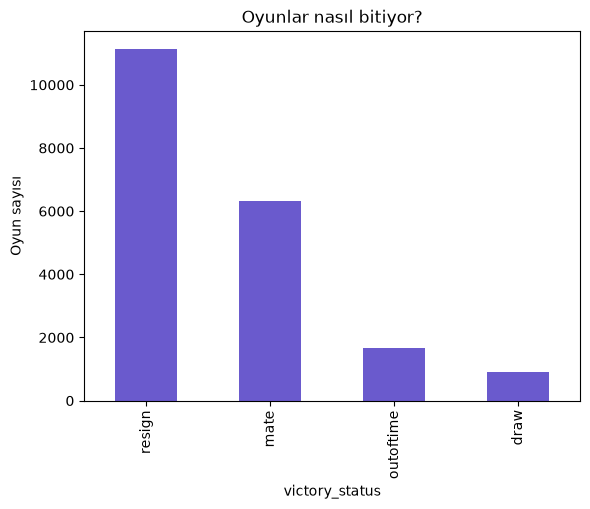

In [58]:
temiz["victory_status"].value_counts().plot(kind="bar", color="slateblue")
plt.title("Oyunlar nasıl bitiyor?")
plt.ylabel("Oyun sayısı")
plt.savefig("cubuk_grafik.png", dpi=150, bbox_inches="tight")
plt.show()

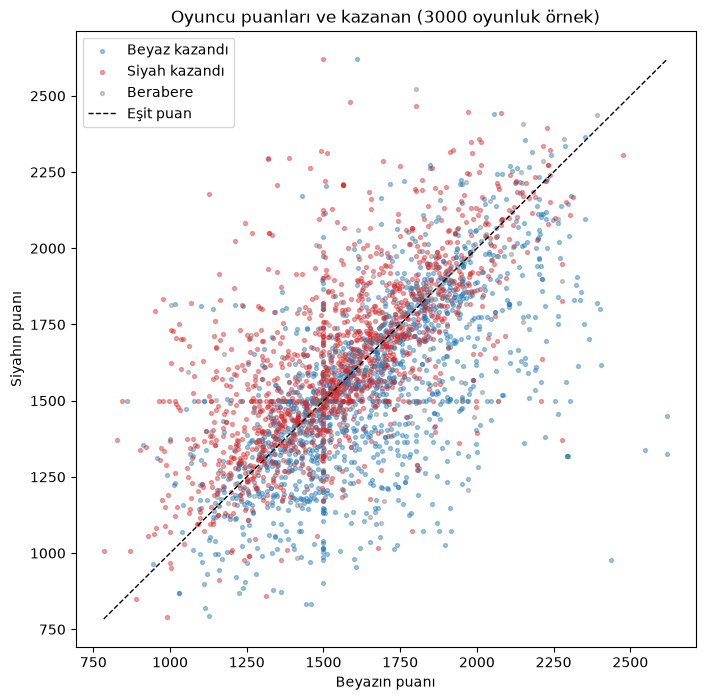

In [57]:
ornek = temiz.sample(3000, random_state=42)

renkler = {
    "white": ("tab:blue", "Beyaz kazandı"),
    "black": ("tab:red", "Siyah kazandı"),
    "draw": ("tab:gray", "Berabere"),
}

fig, ax = plt.subplots(figsize=(8, 8))

for sonuc, (renk, etiket) in renkler.items():
    grup = ornek[ornek["winner"] == sonuc]
    ax.scatter(grup["white_rating"], grup["black_rating"],
               s=8, alpha=0.4, color=renk, label=etiket)

alt = ornek[["white_rating", "black_rating"]].min().min()
ust = ornek[["white_rating", "black_rating"]].max().max()
ax.plot([alt, ust], [alt, ust], "k--", linewidth=1, label="Eşit puan")

ax.set_title("Oyuncu puanları ve kazanan (3000 oyunluk örnek)")
ax.set_xlabel("Beyazın puanı")
ax.set_ylabel("Siyahın puanı")
ax.legend()
plt.savefig("grafik_scatter.png", dpi=150, bbox_inches="tight")
plt.show()